# Q1: Modeling and Analyzing Neural Spike Patterns

**Mini-Project 1 · Neuroscience Data Analysis with Python**

We simulate three neurons over a 5-second recording (regular, irregular and bursting firing), analyze how their spike trains differ, validate the simulation, and examine variability across realizations.

| Section | Owner |
|---|---|
| A. Constructing the models | Yonatan |
| B. Investigating the firing patterns | Junia |
| C. Testing our assumptions | Yonatan |
| D. Investigating new realizations | Yonatan |

## Setup

All randomness goes through a single `numpy.random.Generator` created from a fixed seed, so the notebook gives identical results every time it runs.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42            # global seed for reproducibility
DURATION = 5.0       # recording length in seconds (required by the assignment)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams["figure.dpi"] = 110


def save_fig(fig, name):
    """Save a figure to figures/ with a consistent naming scheme (q1_<name>.png)."""
    path = FIG_DIR / f"q1_{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

## A. Constructing the models
*Owner: Yonatan*

### General approach

Every neuron is described by its **sequence of inter-spike intervals (ISIs)**. A spike train is built by drawing ISIs and taking their cumulative sum:

$$t_k = \sum_{i=1}^{k} \text{ISI}_i$$

Since every ISI is strictly positive, the cumulative sum is **strictly increasing by construction**. This is how we guarantee that spike times are valid and chronologically ordered: we never need to sort. ISIs are drawn in blocks until the running time passes the recording length (5 s), and spikes at or after 5 s are discarded.

The three neurons differ only in **how the ISIs are drawn**. All three are tuned to the **same mean firing rate (10 Hz)**, so that any difference between them comes from the temporal structure of the spikes and not from how many spikes there are. This lets section B test directly whether mean rate alone can distinguish them.

### Modeling assumptions

1. **Regular neuron:** ISIs are nearly constant. Each ISI is the nominal interval (1/rate = 100 ms) plus small Gaussian noise (SD = 2% of the interval), representing small biological fluctuations. Without the noise the model would be fully deterministic.
2. **Irregular neuron:** a **homogeneous Poisson process**. ISIs are independent and exponentially distributed with mean 1/rate. This is the standard model of a neuron firing at random with a constant probability per unit time.
3. **Bursting neuron:** spikes come in bursts of a fixed number of spikes with a short, fixed ISI inside the burst (5 ms). Between bursts there is a quiet period made of a **minimum gap** (50 ms, so bursts never merge) plus an exponentially distributed random part. The random part's mean is chosen so that bursts occur on average at 2 Hz, giving 2 × 5 = 10 spikes/s.
4. **Recording:** spikes are recorded in the interval [0, 5) s. The recording starts at t = 0, so the first spike occurs one ISI after the start.
5. **Not modeled** (simplifications): absolute refractory period for the regular and Poisson neurons, rate changes over time, and interactions between neurons.

### Parameters

| Neuron | Parameter | Value | Meaning | Deterministic / stochastic |
|---|---|---|---|---|
| All | `DURATION` | 5 s | Length of the recording | Deterministic |
| All | `SEED` | 42 | Seed of the random generator | Fixes the stochastic parts |
| Regular | `rate` | 10 Hz | Nominal firing rate → nominal ISI = 100 ms | Deterministic |
| Regular | `jitter_frac` | 0.02 | SD of the ISI noise, as a fraction of the nominal ISI | Controls the stochastic part |
| Irregular | `rate` | 10 Hz | Mean firing rate → mean ISI = 100 ms | ISIs are stochastic (exponential) |
| Bursting | `burst_rate` | 2 Hz | Mean number of bursts per second | Burst timing is stochastic |
| Bursting | `spikes_per_burst` | 5 | Spikes in each burst | Deterministic |
| Bursting | `intra_isi` | 5 ms | ISI inside a burst | Deterministic |
| Bursting | `min_gap` | 50 ms | Minimum quiet interval between bursts | Deterministic |

In [3]:
# ---------- Model parameters (all values documented in the table above) ----------
PARAMS = {
    "regular":   {"rate": 10.0, "jitter_frac": 0.02},
    "irregular": {"rate": 10.0},
    "bursting":  {"burst_rate": 2.0, "spikes_per_burst": 5, "intra_isi": 0.005, "min_gap": 0.050},
}

In [4]:
def _spike_times_from_isis(draw_isis, duration):
    """Turn a generator of ISIs into spike times in [0, duration).

    draw_isis: function with no arguments that returns a 1-D array of positive ISIs (one block).
    Blocks are drawn until the cumulative time passes `duration`; spikes at or after
    `duration` are discarded. Because every ISI is > 0, the result is strictly increasing.
    """
    if duration <= 0:
        return np.array([])
    blocks, t = [], 0.0
    while t < duration:
        isis = np.asarray(draw_isis(), dtype=float)
        if np.any(isis <= 0):
            raise ValueError("All ISIs must be strictly positive.")
        times = t + np.cumsum(isis)
        blocks.append(times)
        t = times[-1]
    spikes = np.concatenate(blocks)
    return spikes[spikes < duration]


def simulate_regular(rate, duration, rng, jitter_frac=0.02):
    """Regular neuron: ISI = 1/rate plus small Gaussian noise (SD = jitter_frac * 1/rate)."""
    if rate <= 0:
        return np.array([])
    nominal_isi = 1.0 / rate
    block = int(duration * rate) + 10

    def draw():
        isis = nominal_isi * (1 + jitter_frac * rng.standard_normal(block))
        # Noise this small never makes an ISI negative, but we guard against it explicitly.
        return np.clip(isis, 1e-4, None)

    return _spike_times_from_isis(draw, duration)


def simulate_irregular(rate, duration, rng):
    """Irregular neuron: homogeneous Poisson process, ISIs ~ Exponential(mean = 1/rate)."""
    if rate <= 0:
        return np.array([])
    block = int(duration * rate) + 10
    return _spike_times_from_isis(lambda: rng.exponential(1.0 / rate, size=block), duration)


def simulate_bursting(burst_rate, spikes_per_burst, intra_isi, min_gap, duration, rng):
    """Bursting neuron: bursts of `spikes_per_burst` spikes separated by `intra_isi`.

    The quiet interval between the last spike of one burst and the first spike of the next is
    min_gap + Exponential(mean_extra), where mean_extra is chosen so that one full burst cycle
    lasts 1/burst_rate seconds on average.
    """
    if burst_rate <= 0 or spikes_per_burst <= 0:
        return np.array([])
    cycle = 1.0 / burst_rate
    mean_extra = cycle - (spikes_per_burst - 1) * intra_isi - min_gap
    if mean_extra <= 0:
        raise ValueError("Burst parameters are inconsistent: bursts would not fit in one cycle.")

    def draw():
        # One cycle = one quiet interval followed by (spikes_per_burst - 1) intra-burst ISIs.
        quiet = min_gap + rng.exponential(mean_extra)
        return np.concatenate([[quiet], np.full(spikes_per_burst - 1, intra_isi)])

    return _spike_times_from_isis(draw, duration)

In [5]:
# ---------- One realization of each neuron, with the global seed ----------
rng = np.random.default_rng(SEED)

spikes = {
    "regular":   simulate_regular(duration=DURATION, rng=rng, **PARAMS["regular"]),
    "irregular": simulate_irregular(duration=DURATION, rng=rng, **PARAMS["irregular"]),
    "bursting":  simulate_bursting(duration=DURATION, rng=rng, **PARAMS["bursting"]),
}

# Quick sanity check that each train is valid (full validation is in section C).
for name, s in spikes.items():
    assert s.ndim == 1 and np.all(np.diff(s) > 0) and s.min() >= 0 and s.max() < DURATION, name
    print(f"{name:<10} {len(s):3d} spikes  ({len(s) / DURATION:.1f} Hz)   first spikes [s]: {np.round(s[:5], 3)}")

regular     49 spikes  (9.8 Hz)   first spikes [s]: [0.101 0.199 0.3   0.402 0.498]
irregular   47 spikes  (9.4 Hz)   first spikes [s]: [0.151 0.682 0.892 1.057 1.161]
bursting    55 spikes  (11.0 Hz)   first spikes [s]: [0.103 0.108 0.113 0.118 0.123]


## B. Investigating the firing patterns
*Owner: Junia*

Design a visual and numerical analysis comparing the three neurons. Our analysis answers:

1. How does each neuron distribute its spikes over time?
2. What can a raster plot reveal?
3. What information is contained in the inter-spike intervals (ISI)?
4. How do the ISI distributions differ?
5. Can mean firing rate alone distinguish the three neurons?
6. Which additional statistics help characterize their firing patterns?

For every figure and statistic, explain **why** it was chosen.

### B.1 Raster plot

In [6]:
# TODO (Junia): raster plot of the three neurons. Save with save_fig(fig, "raster").

### B.2 Inter-spike interval distributions

In [7]:
# TODO (Junia): ISI histograms (np.diff on spike times), one panel per neuron, shared x-axis.
# Save with save_fig(fig, "isi_hist").

### B.3 Summary statistics

In [8]:
# TODO (Junia): table with spike count, mean rate (Hz), mean ISI, ISI std and CV for each neuron.

### B.4 Answers to the questions above
<!-- One short paragraph per question, referring to the figures and the table. -->

## C. Testing our assumptions
*Owner: Yonatan*

A simulation can produce plausible-looking data while implementing the wrong model.
Each check below tests a property that follows from the model we **intended** (section A), not only that the code runs.
Every check uses its own fixed seeds, so the results are reproducible and do not depend on the order in which cells are run.

| # | Type | What it checks | Expected result |
|---|---|---|---|
| 1 | Temporal behavior | Over 200 realizations: spike times are strictly increasing and inside [0, 5) s; in the bursting neuron every ISI is either exactly the intra-burst ISI (5 ms) or at least the minimum gap (50 ms) | No violation in any realization |
| 2 | Statistical property | In a long recording (1000 s): mean rate ≈ 10 Hz for all three neurons; CV of the ISIs ≈ 0.02 (regular), ≈ 1 (Poisson), > 1 (bursting); Poisson ISIs follow an exponential distribution | Values within tolerance of theory; KS test does not reject the exponential |
| 3 | Edge cases | Same seed → identical output; different seed → different output; zero rate, zero duration and very short recordings return valid (possibly empty) trains; impossible burst parameters raise an error | All cases behave as specified |
| 4 | Parameter sensitivity | Raising `jitter_frac` raises the CV of the regular neuron; doubling the rate doubles the number of spikes | Effects go in the expected direction and size |

In [9]:
# ---------- Check 1: temporal behavior ----------
def is_valid_train(s, duration):
    """True if s is a 1-D, strictly increasing array of times inside [0, duration)."""
    return s.ndim == 1 and np.all(np.diff(s) > 0) and (len(s) == 0 or (s[0] >= 0 and s[-1] < duration))

N_REAL = 200
bp = PARAMS["bursting"]
problems = 0

for seed in range(N_REAL):
    rng_c = np.random.default_rng(1000 + seed)
    trains = {
        "regular":   simulate_regular(duration=DURATION, rng=rng_c, **PARAMS["regular"]),
        "irregular": simulate_irregular(duration=DURATION, rng=rng_c, **PARAMS["irregular"]),
        "bursting":  simulate_bursting(duration=DURATION, rng=rng_c, **bp),
    }
    for name, s in trains.items():
        if not is_valid_train(s, DURATION):
            problems += 1
            print(f"Invalid train: {name}, seed {seed}")

    # Bursting structure: each ISI is either the intra-burst ISI or a quiet gap >= min_gap.
    isi_b = np.diff(trains["bursting"])
    is_intra = np.isclose(isi_b, bp["intra_isi"])
    is_gap = isi_b >= bp["min_gap"] - 1e-12
    if not np.all(is_intra | is_gap):
        problems += 1
        print(f"Bursting ISI outside the model, seed {seed}: {isi_b[~(is_intra | is_gap)]}")

assert problems == 0, f"{problems} problems found"
print(f"Check 1 passed: {N_REAL} realizations x 3 neurons, all trains valid and ordered;")
print(f"bursting ISIs are only {bp['intra_isi'] * 1000:.0f} ms (inside bursts) or >= {bp['min_gap'] * 1000:.0f} ms (between bursts).")

Check 1 passed: 200 realizations x 3 neurons, all trains valid and ordered;
bursting ISIs are only 5 ms (inside bursts) or >= 50 ms (between bursts).


In [10]:
# ---------- Check 2: statistical properties (long recording) ----------
from scipy import stats

LONG = 1000.0          # seconds: long enough for estimates to be close to their theoretical values
rng_c = np.random.default_rng(2024)
long_trains = {
    "regular":   simulate_regular(duration=LONG, rng=rng_c, **PARAMS["regular"]),
    "irregular": simulate_irregular(duration=LONG, rng=rng_c, **PARAMS["irregular"]),
    "bursting":  simulate_bursting(duration=LONG, rng=rng_c, **PARAMS["bursting"]),
}

rows = []
for name, s in long_trains.items():
    isi = np.diff(s)
    rows.append({"neuron": name, "spikes": len(s), "rate_Hz": len(s) / LONG,
                 "mean_ISI_ms": isi.mean() * 1000, "CV": isi.std() / isi.mean()})
check2 = pd.DataFrame(rows).set_index("neuron").round(3)
display(check2)

# Expected values follow directly from the model definitions in section A.
assert abs(check2.loc["regular", "rate_Hz"] - 10) < 0.2
assert abs(check2.loc["irregular", "rate_Hz"] - 10) < 0.5
assert abs(check2.loc["bursting", "rate_Hz"] - 10) < 0.5
assert abs(check2.loc["regular", "CV"] - PARAMS["regular"]["jitter_frac"]) < 0.005   # CV of regular = jitter_frac
assert abs(check2.loc["irregular", "CV"] - 1) < 0.05                                 # CV of an exponential = 1
assert check2.loc["bursting", "CV"] > 1.5                                            # mixture of 5 ms and long gaps

# Poisson ISIs should be exponential with mean 1/rate: Kolmogorov-Smirnov test against that distribution.
isi_p = np.diff(long_trains["irregular"])
ks = stats.kstest(isi_p, "expon", args=(0, 1 / PARAMS["irregular"]["rate"]))
print(f"KS test, Poisson ISIs vs Exponential(mean = 100 ms): D = {ks.statistic:.4f}, p = {ks.pvalue:.3f}")
assert ks.pvalue > 0.01, "Poisson ISIs do not look exponential"
print("Check 2 passed: rates and CVs match the model; Poisson ISIs are consistent with an exponential distribution.")

,spikes,rate_Hz,mean_ISI_ms,CV
neuron,,,,
regular,9998,9.998,100.015,0.020
irregular,10007,10.007,99.909,1.001
bursting,10135,10.135,98.629,2.712


KS test, Poisson ISIs vs Exponential(mean = 100 ms): D = 0.0076, p = 0.601
Check 2 passed: rates and CVs match the model; Poisson ISIs are consistent with an exponential distribution.


In [11]:
# ---------- Check 3: edge cases ----------
p = PARAMS

# (a) Reproducibility: the same seed gives identical spikes, a different seed gives different spikes.
a = simulate_irregular(duration=DURATION, rng=np.random.default_rng(7), **p["irregular"])
b = simulate_irregular(duration=DURATION, rng=np.random.default_rng(7), **p["irregular"])
c = simulate_irregular(duration=DURATION, rng=np.random.default_rng(8), **p["irregular"])
assert np.array_equal(a, b), "same seed should reproduce the same train"
assert not np.array_equal(a, c), "different seeds should give different trains"

# (b) Zero rate or zero duration: an empty train, no crash and no infinite loop.
rng_c = np.random.default_rng(0)
assert len(simulate_regular(rate=0, duration=DURATION, rng=rng_c)) == 0
assert len(simulate_irregular(rate=0, duration=DURATION, rng=rng_c)) == 0
assert len(simulate_irregular(rate=10, duration=0, rng=rng_c)) == 0
assert len(simulate_bursting(burst_rate=0, spikes_per_burst=5, intra_isi=0.005, min_gap=0.05,
                             duration=DURATION, rng=rng_c)) == 0

# (c) Very short recording (50 ms, shorter than one regular ISI): still a valid train.
for name, f in [("regular", simulate_regular), ("irregular", simulate_irregular), ("bursting", simulate_bursting)]:
    s = f(duration=0.05, rng=np.random.default_rng(3), **p[name])
    assert is_valid_train(s, 0.05), name
print("Very short recording (50 ms): regular has",
      len(simulate_regular(duration=0.05, rng=np.random.default_rng(3), **p["regular"])), "spikes (expected 0: first spike at ~100 ms)")

# (d) Impossible bursting parameters (bursts longer than one cycle) must raise an error, not run silently.
try:
    simulate_bursting(burst_rate=20, spikes_per_burst=10, intra_isi=0.01, min_gap=0.05, duration=DURATION, rng=rng_c)
    raise AssertionError("expected a ValueError for inconsistent burst parameters")
except ValueError as e:
    print("Inconsistent burst parameters correctly rejected:", e)

print("Check 3 passed: reproducible, and zero / very short / impossible inputs are handled correctly.")

Very short recording (50 ms): regular has 0 spikes (expected 0: first spike at ~100 ms)
Inconsistent burst parameters correctly rejected: Burst parameters are inconsistent: bursts would not fit in one cycle.
Check 3 passed: reproducible, and zero / very short / impossible inputs are handled correctly.


In [12]:
# ---------- Check 4: changing a parameter has the expected effect ----------
def mean_cv(sim, n=100, **kw):
    """Average CV of the ISIs over n realizations of 5 s."""
    cvs = []
    for seed in range(n):
        isi = np.diff(sim(duration=DURATION, rng=np.random.default_rng(seed), **kw))
        cvs.append(isi.std() / isi.mean())
    return np.mean(cvs)

jitters = [0.01, 0.05, 0.10, 0.20]
cv_by_jitter = [mean_cv(simulate_regular, rate=10, jitter_frac=j) for j in jitters]
for j, cv in zip(jitters, cv_by_jitter):
    print(f"jitter_frac = {j:.2f}  ->  mean CV = {cv:.3f}")
assert np.all(np.diff(cv_by_jitter) > 0), "CV should increase with jitter"

n10 = np.mean([len(simulate_irregular(rate=10, duration=DURATION, rng=np.random.default_rng(s))) for s in range(200)])
n20 = np.mean([len(simulate_irregular(rate=20, duration=DURATION, rng=np.random.default_rng(s))) for s in range(200)])
print(f"Poisson: mean spikes at 10 Hz = {n10:.1f}, at 20 Hz = {n20:.1f}  (ratio {n20 / n10:.2f}, expected 2)")
assert abs(n20 / n10 - 2) < 0.1
print("Check 4 passed: the parameters control the properties they are supposed to control.")

jitter_frac = 0.01  ->  mean CV = 0.010
jitter_frac = 0.05  ->  mean CV = 0.048
jitter_frac = 0.10  ->  mean CV = 0.095
jitter_frac = 0.20  ->  mean CV = 0.190
Poisson: mean spikes at 10 Hz = 50.6, at 20 Hz = 100.5  (ratio 1.99, expected 2)
Check 4 passed: the parameters control the properties they are supposed to control.


### What the checks show

- **Check 1 (temporal):** in 200 realizations of each neuron, every spike train was strictly increasing and inside the 5 s recording. In the bursting neuron every ISI was either exactly 5 ms or at least 50 ms, so bursts never merge and nothing appears outside the intended structure.
- **Check 2 (statistical):** in a 1000 s recording all three neurons fire at ≈ 10 Hz, as designed. The CV matches theory: ≈ 0.02 for the regular neuron (equal to `jitter_frac`), ≈ 1 for the Poisson neuron (the CV of an exponential distribution), and well above 1 for the bursting neuron. The KS test does not reject an exponential distribution for the Poisson ISIs (p = 0.60).
- **Check 3 (edge cases):** the same seed reproduces the same train exactly. Zero rate, zero duration and a 50 ms recording return valid trains (empty where expected) instead of crashing or looping forever, and impossible burst parameters raise a clear error.
- **Check 4 (parameters):** increasing the jitter increases the variability of the regular neuron (CV 0.01 → 0.19), and doubling the Poisson rate doubles the spike count (ratio 1.99). The parameters control what the model description says they control.

Together these checks support that the code implements the models described in section A, and not just something that looks plausible.

## D. Investigating new realizations
*Owner: Yonatan*

A single 5-second recording is one random sample of what a neuron can produce. Here we generate **100 new realizations** of every model (new seeds, same parameters) and ask:

- How much do spike patterns vary between realizations?
- Can two realizations of the same neuron model look quite different?
- Which properties remain relatively stable?

For each realization we measure the spike count (→ mean rate), the CV of the ISIs, and the fraction of ISIs shorter than 10 ms (a direct marker of bursts).
Seeds 5000–5099 are used here, so these realizations are independent of the ones used in sections A and C.

In [13]:
# ---------- D.1 Generate 100 new realizations of each model and measure them ----------
N_REAL_D = 100
SIMULATORS = {"regular": simulate_regular, "irregular": simulate_irregular, "bursting": simulate_bursting}
COLORS = {"regular": "#534AB7", "irregular": "#0F6E56", "bursting": "#993C1D"}


def describe_train(s, duration=DURATION):
    """Summary measures of one spike train."""
    isi = np.diff(s)
    return {
        "n_spikes": len(s),
        "rate_Hz": len(s) / duration,
        "CV": isi.std() / isi.mean() if len(isi) > 1 else np.nan,
        "frac_ISI_below_10ms": np.mean(isi < 0.010) if len(isi) > 0 else np.nan,
    }


def run_realizations(seeds):
    """Simulate every model once per seed and return one row per (neuron, seed)."""
    rows, trains = [], {name: [] for name in SIMULATORS}
    for seed in seeds:
        for name, sim in SIMULATORS.items():
            s = sim(duration=DURATION, rng=np.random.default_rng(seed), **PARAMS[name])
            trains[name].append(s)
            rows.append({"neuron": name, "seed": seed, **describe_train(s)})
    return pd.DataFrame(rows), trains


real_df, real_trains = run_realizations(range(5000, 5000 + N_REAL_D))

summary_d = (real_df.groupby("neuron", sort=False)[["rate_Hz", "CV", "frac_ISI_below_10ms"]]
             .agg(["mean", "std", "min", "max"]).round(3))
display(summary_d)

rate_Hz                       CV                       \
             mean    std  min   max   mean    std    min    max   
neuron                                                            
regular     9.902  0.100  9.8  10.0  0.020  0.002  0.015  0.024   
irregular   9.998  1.234  7.2  13.4  0.980  0.141  0.698  1.356   
bursting    9.924  2.721  4.0  16.0  2.623  0.296  2.123  3.783   

          frac_ISI_below_10ms                     
                         mean    std  min    max  
neuron                                            
regular                 0.000  0.000  0.0  0.000  
irregular               0.098  0.042  0.0  0.185  
bursting                0.818  0.007  0.8  0.842

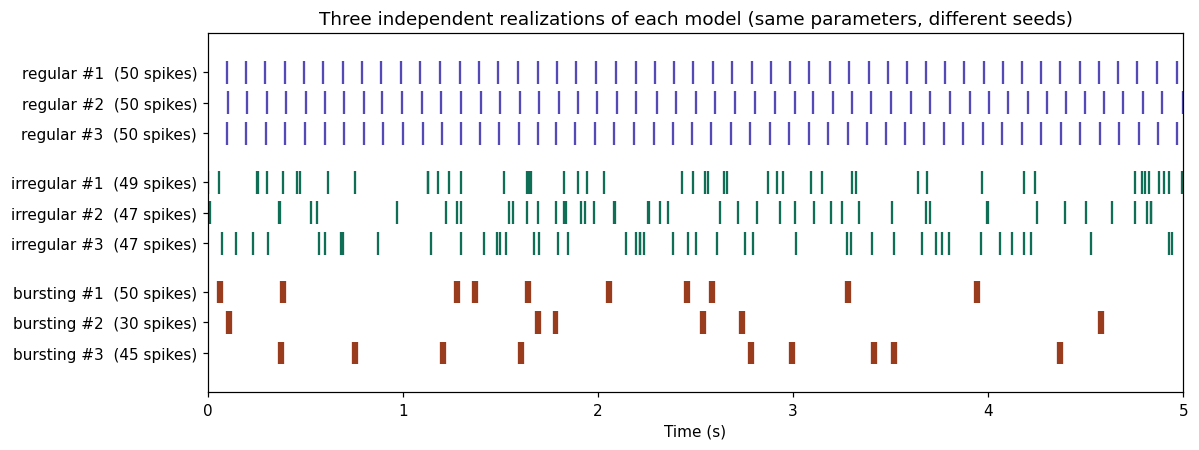

In [14]:
# ---------- D.2 Do realizations of the same model look different? ----------
fig, ax = plt.subplots(figsize=(11, 4.2))
offset, yticks, ylabels = 0, [], []
for name in SIMULATORS:
    for k in range(3):                                  # the first three realizations of each model
        ax.eventplot(real_trains[name][k], lineoffsets=offset, linelengths=0.75, colors=COLORS[name])
        n = len(real_trains[name][k])
        yticks.append(offset)
        ylabels.append(f"{name} #{k + 1}  ({n} spikes)")
        offset -= 1
    offset -= 0.6                                       # gap between the three models
ax.set_yticks(yticks)
ax.set_yticklabels(ylabels)
ax.set_xlim(0, DURATION)
ax.set_xlabel("Time (s)")
ax.set_title("Three independent realizations of each model (same parameters, different seeds)")
fig.tight_layout()
save_fig(fig, "realizations_raster")
plt.show()

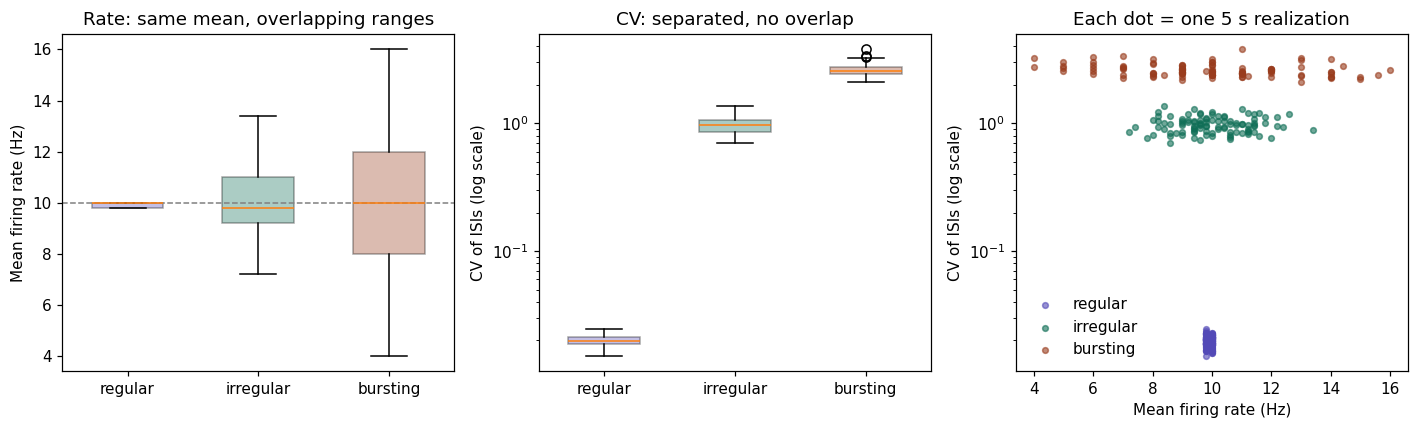

In [15]:
# ---------- D.3 Which properties vary and which are stable across realizations? ----------
names = list(SIMULATORS)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Mean rate: overlaps between the models
data = [real_df.loc[real_df.neuron == n, "rate_Hz"] for n in names]
bp_ = axes[0].boxplot(data, patch_artist=True, widths=0.55)
for patch, n in zip(bp_["boxes"], names):
    patch.set_facecolor(COLORS[n]); patch.set_alpha(0.35)
axes[0].axhline(10, ls="--", lw=1, color="gray")
axes[0].set_xticks([1, 2, 3], names)
axes[0].set_ylabel("Mean firing rate (Hz)")
axes[0].set_title("Rate: same mean, overlapping ranges")

# CV: clearly separated (log scale because the values span two orders of magnitude)
data = [real_df.loc[real_df.neuron == n, "CV"] for n in names]
bp_ = axes[1].boxplot(data, patch_artist=True, widths=0.55)
for patch, n in zip(bp_["boxes"], names):
    patch.set_facecolor(COLORS[n]); patch.set_alpha(0.35)
axes[1].set_yscale("log")
axes[1].set_xticks([1, 2, 3], names)
axes[1].set_ylabel("CV of ISIs (log scale)")
axes[1].set_title("CV: separated, no overlap")

# Each realization as one point: rate vs CV
for n in names:
    sub = real_df[real_df.neuron == n]
    axes[2].scatter(sub["rate_Hz"], sub["CV"], s=14, alpha=0.6, color=COLORS[n], label=n)
axes[2].set_yscale("log")
axes[2].set_xlabel("Mean firing rate (Hz)")
axes[2].set_ylabel("CV of ISIs (log scale)")
axes[2].set_title("Each dot = one 5 s realization")
axes[2].legend(frameon=False)

fig.tight_layout()
save_fig(fig, "realizations_stats")
plt.show()

### Turning the observation into a rule

The figures suggest that the **CV of the ISIs** separates the three models in every realization, while the mean rate does not.
We turn this into an explicit rule and test it on **200 new realizations of each model** (seeds 9000–9199, 600 in total) that were not used to choose the thresholds:

| CV of the ISIs | Classified as |
|---|---|
| CV < 0.3 | regular |
| 0.3 ≤ CV < 1.5 | irregular (Poisson-like) |
| CV ≥ 1.5 | bursting |

The thresholds sit in the wide gaps between the groups seen in D.3 and between the theoretical values (≈ 0.02, 1 and > 1.5). For comparison we also try to classify using the mean rate alone.

In [16]:
# ---------- D.4 Test the CV rule on new, held-out realizations ----------
def classify_by_cv(cv):
    if cv < 0.3:
        return "regular"
    if cv < 1.5:
        return "irregular"
    return "bursting"


test_df, _ = run_realizations(range(9000, 9200))
test_df["predicted"] = test_df["CV"].apply(classify_by_cv)
accuracy_cv = (test_df["predicted"] == test_df["neuron"]).mean()
print(f"CV rule: {accuracy_cv:.1%} of {len(test_df)} held-out realizations classified correctly")
display(pd.crosstab(test_df["neuron"], test_df["predicted"], rownames=["true"], colnames=["predicted"]))

# Mean rate alone: how much do the three models overlap?
rate_ranges = test_df.groupby("neuron", sort=False)["rate_Hz"].agg(["min", "max"]).round(1)
print("\nRange of mean rates in the held-out realizations (Hz):")
display(rate_ranges)

assert accuracy_cv > 0.95, "the CV rule should separate the models almost perfectly"

CV rule: 100.0% of 600 held-out realizations classified correctly


predicted,bursting,irregular,regular
true,,,
bursting,200,0,0
irregular,0,200,0
regular,0,0,200



Range of mean rates in the held-out realizations (Hz):


,min,max
neuron,,
regular,9.8,10.0
irregular,7.4,13.4
bursting,3.0,20.0


### Answers

**How much do spike patterns vary between realizations?**
The exact spike times are different in every realization: no two rasters in D.2 are the same, even with identical parameters. The amount of variation depends on the model. The regular neuron hardly changes: its spike count is almost always 49 or 50. The irregular neuron's rate varies with an SD of about 1.2 Hz around 10 Hz (from 7.2 to 13.4 Hz in 100 realizations), as expected from a Poisson process, whose spike count has a variance equal to its mean. The bursting neuron varies the most (from 4 to 16 Hz, SD ≈ 2.7 Hz), because its spikes come in groups of five: one burst more or less changes the rate by 1 Hz, and in 5 s there are only about 10 bursts.

**Can two realizations of the same model look quite different?**
Yes, for the stochastic models. Two bursting realizations can differ by several bursts and leave long silent stretches in different places, and two Poisson realizations can differ by more than 2 Hz in mean rate. Judged by eye, or by rate alone, a single 5 s recording can be misleading.

**Which properties remain relatively stable?**
The **shape of the ISI distribution**, summarized by the CV, is stable: it stays in a narrow band for each model (0.015–0.024 regular, 0.70–1.36 irregular, 2.1–3.8 bursting in 100 realizations) and the three bands never overlap (D.3). The fraction of very short ISIs (< 10 ms) is also stable: 0 for the regular neuron, ≈ 10% for the Poisson neuron, and ≈ 82% for the bursting neuron (4 out of every 5 ISIs are inside a burst). The **mean rate is not a reliable signature**: all three models share the same expected rate and their single-recording rates overlap.

**How would we distinguish the three firing patterns from observations?**
We would not rely on the mean firing rate. We would compute the ISIs of the recording and look at their variability and shape:
1. **CV ≪ 1** with a narrow, single-peaked ISI histogram → **regular** firing.
2. **CV ≈ 1** with an exponential-looking ISI histogram (many short intervals, a long tail) → **irregular, Poisson-like** firing.
3. **CV > 1** with a **bimodal** ISI histogram (a sharp peak at a few ms plus a broad peak of long gaps) and many ISIs below 10 ms → **bursting**.

The simple CV rule classified all 600 held-out realizations correctly (D.4), even though their mean rates overlapped widely (Poisson 7.4–13.4 Hz, bursting 3–20 Hz). The upper threshold (1.5) is the tighter one: the most variable Poisson realizations reached CV ≈ 1.4, so for shorter recordings the two groups would start to overlap.

**Limitations:** this works because our models are well separated by design. Real neurons can fall between these categories (e.g. a Poisson neuron with a refractory period has CV < 1), their rate can change over time, and short recordings give noisier estimates. With real data we would therefore also look at the ISI histogram itself and not only at a single number.

### Distinguishing the three firing patterns from observations
<!-- How would we tell the three patterns apart from recorded data, without knowing how they were generated? -->

## Model description and scientific interpretation
<!-- Required for submission: a brief description of the models and assumptions, and a short scientific interpretation. -->

### Models and assumptions

### Interpretation